In [1]:
from sklearn.datasets import fetch_openml
# Option 1 -- Adult / Census Income
adult = fetch_openml(name="adult", version=2, as_frame=True)
X, y = adult.data, adult.target

In [2]:
print(adult.DESCR)

**Author**: Ronny Kohavi and Barry Becker  
**Source**: [UCI](https://archive.ics.uci.edu/ml/datasets/Adult) - 1996  
**Please cite**: Ron Kohavi, "Scaling Up the Accuracy of Naive-Bayes Classifiers: a Decision-Tree Hybrid", Proceedings of the Second International Conference on Knowledge Discovery and Data Mining, 1996  

Prediction task is to determine whether a person makes over 50K a year. Extraction was done by Barry Becker from the 1994 Census database. A set of reasonably clean records was extracted using the following conditions: ((AAGE>16) && (AGI>100) && (AFNLWGT>1)&& (HRSWK>0))

This is the original version from the UCI repository, with training and test sets merged.

### Variable description

Variables are all self-explanatory except __fnlwgt__. This is a proxy for the demographic background of the people: "People with similar demographic characteristics should have similar weights". This similarity-statement is not transferable across the 51 different states.

Description f

# EDA — Adult / Census Income

## Step 1 — Context

**1. Where does each row come from?**
Each row is one person who answered the 1994 Current Population Survey (CPS),
run by the U.S. Census Bureau. The data was extracted by Barry Becker and
published by Ronny Kohavi and Barry Becker (1996) on the UCI Machine Learning
Repository. The OpenML version merges the original train and test files,
which gives 48,842 rows.

Only "reasonably clean" records were kept: age above 16, adjusted gross income
above $100, sampling weight above 1, and more than 0 hours worked per week.
The dataset therefore represents working adults with some income, not the
whole U.S. population.

**2. When is each feature measured?**
All features come from the same survey answers, collected at the same time
as the income. There is no timestamp and no feature measured before the
income: the data is a single snapshot.
*Assumption:* features describe the person's situation in the same year as
the income they reported.

**3. What does the target mean?**
`class` indicates whether the person's self-reported annual income in 1994
was above $50,000. The exact amount was removed; only the yes/no label remains.
Limits: income is self-reported, the $50K threshold is arbitrary, the data
is U.S.-only, and $50K in 1994 is worth much more today (inflation).

**4. Which business process generated the data?**
The CPS is a monthly government survey that measures employment and income
for official statistics. It was not collected to predict income: the
prediction task was created afterwards by researchers as a benchmark.
We will define our own business use case in Step 5.

## Step 2 — Integrity & target

In [3]:
import pandas as pd
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

In [4]:
df = adult.frame.copy()   # working copy, no new column

# 1. Size
print("Shape:", df.shape)

# 2. Data types
display(df.dtypes)

# 3. Missing values per column
missing = df.isna().sum()
display(pd.DataFrame({
    "missing": missing,
    "share_%": (missing / len(df) * 100).round(2)
})[missing > 0])

# 4. Do workclass and occupation go missing together?
print("workclass missing:", df["workclass"].isna().sum())
print("occupation missing:", df["occupation"].isna().sum())
print("both missing:", (df["workclass"].isna() & df["occupation"].isna()).sum())

# 5. Duplicated rows
print("Duplicated rows:", df.duplicated().sum(),
      f"({df.duplicated().mean()*100:.2f}%)")

# 6. Target balance, directly from class
display(df["class"].value_counts())
display((df["class"].value_counts(normalize=True) * 100).round(2))

Shape: (48842, 15)


age                  int64
workclass         category
fnlwgt               int64
education         category
education-num        int64
marital-status    category
occupation        category
relationship      category
race              category
sex               category
capital-gain         int64
capital-loss         int64
hours-per-week       int64
native-country    category
class             category
dtype: object

,missing,share_%
workclass,2799,5.73
occupation,2809,5.75
native-country,857,1.75


workclass missing: 2799
occupation missing: 2809
both missing: 2799
Duplicated rows: 52 (0.11%)


class
<=50K    37155
>50K     11687
Name: count, dtype: int64

class
<=50K    76.07
>50K     23.93
Name: proportion, dtype: float64

In [5]:
only_occ = df["occupation"].isna() & df["workclass"].notna()
display(df.loc[only_occ, "workclass"].value_counts())

workclass
Never-worked        10
Federal-gov          0
Local-gov            0
Private              0
Self-emp-inc         0
Self-emp-not-inc     0
State-gov            0
Without-pay          0
Name: count, dtype: int64

### Step 2 — Findings & decisions

**Size**
- 48,842 rows × 15 columns, as documented.

**Missing values**
- Only 3 columns have missing values: `workclass` (5.73%), `occupation` (5.75%),
  `native-country` (1.75%). The documentation does not mention them.
- All 2,799 rows missing `workclass` also miss `occupation`: the missingness is
  not random, it affects the same people.
- The 10 extra rows missing `occupation` only all have `workclass = Never-worked`:
  for them, occupation is not unknown but *not applicable*.

→ **Decisions**
- Keep all rows (no deletion).
- Set `occupation = "Never-worked"` for these 10 rows (fixed rule, in the cleaning step).
- Impute the remaining missing values with an "Unknown" category inside the Pipeline.

**Duplicates**
- 52 exact duplicate rows (0.11%), identical even on `fnlwgt`.

→ **Decision:** drop them.
*Assumption:* they are repeated records (possibly from merging the train and
test files), not distinct people.

**Target**
- `<=50K`: 37,155 (76.07%) · `>50K`: 11,687 (23.93%) → imbalanced.

→ **Decisions**
- Stratify the split to keep ~24% `>50K` in every subset.
- Do not rely on accuracy: always predicting `<=50K` would already score 76%.

## Step 3 — Storage type vs semantic type

In [6]:
# 1. How many different values does each column have?
display(df.nunique().sort_values())

# 2. The categories of each categorical column
for col in df.select_dtypes("category").columns:
    print(f"\n{col} ({df[col].nunique()} values):")
    print(list(df[col].cat.categories))

# 3. Does education-num match education one-to-one?
display(df.groupby("education", observed=True)["education-num"].unique())

sex                   2
class                 2
race                  5
relationship          6
marital-status        7
workclass             8
occupation           14
education            16
education-num        16
native-country       41
age                  74
hours-per-week       96
capital-loss         99
capital-gain        123
fnlwgt            28523
dtype: int64


workclass (8 values):
['Federal-gov', 'Local-gov', 'Never-worked', 'Private', 'Self-emp-inc', 'Self-emp-not-inc', 'State-gov', 'Without-pay']

education (16 values):
['10th', '11th', '12th', '1st-4th', '5th-6th', '7th-8th', '9th', 'Assoc-acdm', 'Assoc-voc', 'Bachelors', 'Doctorate', 'HS-grad', 'Masters', 'Preschool', 'Prof-school', 'Some-college']

marital-status (7 values):
['Divorced', 'Married-AF-spouse', 'Married-civ-spouse', 'Married-spouse-absent', 'Never-married', 'Separated', 'Widowed']

occupation (14 values):
['Adm-clerical', 'Armed-Forces', 'Craft-repair', 'Exec-managerial', 'Farming-fishing', 'Handlers-cleaners', 'Machine-op-inspct', 'Other-service', 'Priv-house-serv', 'Prof-specialty', 'Protective-serv', 'Sales', 'Tech-support', 'Transport-moving']

relationship (6 values):
['Husband', 'Not-in-family', 'Other-relative', 'Own-child', 'Unmarried', 'Wife']

race (5 values):
['Amer-Indian-Eskimo', 'Asian-Pac-Islander', 'Black', 'Other', 'White']

sex (2 values):
['Female', 'M

education
10th             [6]
11th             [7]
12th             [8]
1st-4th          [2]
5th-6th          [3]
7th-8th          [4]
9th              [5]
Assoc-acdm      [12]
Assoc-voc       [11]
Bachelors       [13]
Doctorate       [16]
HS-grad          [9]
Masters         [14]
Preschool        [1]
Prof-school     [15]
Some-college    [10]
Name: education-num, dtype: object

In [7]:
display(pd.crosstab(df["relationship"], df["marital-status"]))

marital-status,Divorced,Married-AF-spouse,Married-civ-spouse,Married-spouse-absent,Never-married,Separated,Widowed
relationship,,,,,,,
Husband,0,12,19704,0,0,0,0
Not-in-family,3628,0,23,330,7114,637,851
Other-relative,181,1,201,54,920,79,70
Own-child,455,1,143,61,6750,146,25
Unmarried,2369,0,0,183,1333,668,572
Wife,0,23,2308,0,0,0,0


### Step 3 — Findings & decisions

**Semantic types**

| Column | Stored as | Really is | Why |
|---|---|---|---|
| `sex` | category (2) | **Binary** | Female / Male as recorded in the 1994 survey; sensitive attribute |
| `race` | category (5) | **Nominal** (no order) | Sensitive attribute; includes a vague "Other" group |
| `relationship` | category (6) | **Nominal** | Role in the household; Husband/Wife reveal sex (proxy) |
| `marital-status` | category (7) | **Nominal** | Legal status; overlaps with `relationship` |
| `workclass` | category (8) | **Nominal** | |
| `occupation` | category (14) | **Nominal** | |
| `native-country` | category (41) | **Nominal, many categories** | Probably dominated by United-States (Step 4) |
| `education` | category (16) | **Ordinal** | Pandas sorts it alphabetically: the real order is lost |
| `education-num` | int (16) | **Ordinal** | Same information as `education`, order kept |
| `age`, `hours-per-week` | int (74, 96) | **Numerical** | Real quantities |
| `capital-gain`, `capital-loss` | int (123, 99) | **Numerical but sparse** | Few distinct values: probably mostly zeros (Step 4) |
| `fnlwgt` | int (28,523) | **Sampling weight** | Not a trait of the person (see documentation) |

**Findings**
- `education` and `education-num` match one-to-one (16 levels each):
  same information twice.
- Missing values are true NaN, not hidden text categories ("?").
- `relationship` × `marital-status` crosstab:
  - all Husbands (19,716) and Wives (2,331) are married → for them,
    `relationship` only adds the sex of the person;
  - the only extra information is `Own-child` (living with parents),
    mostly young never-married people, largely captured by `age`.
- `Married-AF-spouse` has only 37 people.
- *Open question:* 23 people are `Not-in-family` but `Married-civ-spouse`,
  and 201 are `Other-relative` and married. Possible but unusual; too few
  to affect the model.

→ **Decisions**
- Drop `education`, keep `education-num` (no information lost).
- Drop `relationship`, keep `marital-status`: little extra information,
  and it is a strong proxy for `sex`.
- Group `Married-AF-spouse` into `Married-civ-spouse` (too rare, same meaning).
- Nominal columns (`workclass`, `marital-status`, `occupation`, `race`, `sex`)
  → one-hot encoding in the Pipeline.
- `native-country` → group rare countries into "Other" (rule set in Step 4).
- Whether `sex` and `race` are used as model inputs → fairness audit (req. 10).
- `fnlwgt` → decision in Step 6.

## Step 4 — Data up close

### Step 4a — Ranges & documentation checks

In [8]:
num_cols = ["age", "fnlwgt", "education-num", "capital-gain", "capital-loss", "hours-per-week"]

# 1. Min, max, mean, quartiles for the numeric columns
display(df[num_cols].describe().round(1))

# 2. Does the data respect the documented filters?
print("Minimum age (doc says > 16):", df["age"].min())
print("Minimum hours/week (doc says > 0):", df["hours-per-week"].min())
print("Minimum fnlwgt (doc says > 1):", df["fnlwgt"].min())

# 3. "Never-worked" people: how many hours do they work?
display(df.loc[df["workclass"] == "Never-worked", ["age", "hours-per-week", "occupation", "class"]])

# 4. Five random people, to see what real rows look like
display(df.sample(5, random_state=42))

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.0,48842.0,48842.0,48842.0,48842.0,48842.0
mean,38.6,189664.1,10.1,1079.1,87.5,40.4
std,13.7,105604.0,2.6,7452.0,403.0,12.4
min,17.0,12285.0,1.0,0.0,0.0,1.0
25%,28.0,117550.5,9.0,0.0,0.0,40.0
50%,37.0,178144.5,10.0,0.0,0.0,40.0
75%,48.0,237642.0,12.0,0.0,0.0,45.0
max,90.0,1490400.0,16.0,99999.0,4356.0,99.0


Minimum age (doc says > 16): 17
Minimum hours/week (doc says > 0): 1
Minimum fnlwgt (doc says > 1): 12285


,age,hours-per-week,occupation,class
8785,17,20,NaN,<=50K
11607,20,35,NaN,<=50K
13898,18,35,NaN,<=50K
21642,18,40,NaN,<=50K
27126,23,35,NaN,<=50K
31053,17,30,NaN,<=50K
36618,18,10,NaN,<=50K
39513,20,40,NaN,<=50K
48585,30,40,NaN,<=50K
48595,18,4,NaN,<=50K


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
7762,56,Private,33115,HS-grad,9,Divorced,Other-service,Unmarried,White,Female,0,0,40,United-States,<=50K
23881,25,Private,112847,HS-grad,9,Married-civ-spouse,Transport-moving,Own-child,Other,Male,0,0,40,United-States,<=50K
30507,43,Private,170525,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,14344,0,40,United-States,>50K
28911,32,Private,186788,HS-grad,9,Married-civ-spouse,Transport-moving,Husband,White,Male,0,0,40,United-States,<=50K
19484,39,Private,277886,Bachelors,13,Married-civ-spouse,Sales,Wife,White,Female,0,0,30,United-States,<=50K


### Step 4b — Distributions, outliers & rare categories

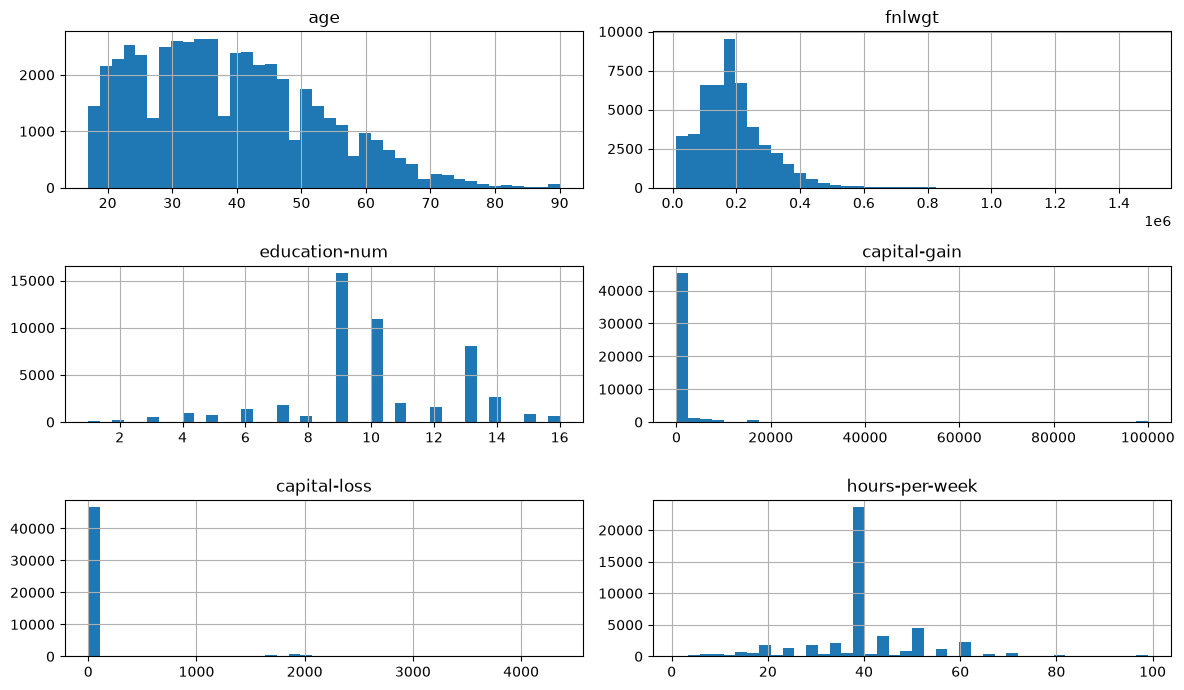

capital-gain: 91.7% zeros
capital-loss: 95.3% zeros
capital-gain = 99,999: 244
hours-per-week = 99: 137
age = 90: 55

workclass


,count,share_%
workclass,,
Private,33906,69.42
Self-emp-not-inc,3862,7.91
Local-gov,3136,6.42
NaN,2799,5.73
State-gov,1981,4.06
Self-emp-inc,1695,3.47
Federal-gov,1432,2.93
Without-pay,21,0.04
Never-worked,10,0.02



marital-status


,count,share_%
marital-status,,
Married-civ-spouse,22379,45.82
Never-married,16117,33.00
Divorced,6633,13.58
Separated,1530,3.13
Widowed,1518,3.11
Married-spouse-absent,628,1.29
Married-AF-spouse,37,0.08



occupation


,count,share_%
occupation,,
Prof-specialty,6172,12.64
Craft-repair,6112,12.51
Exec-managerial,6086,12.46
Adm-clerical,5611,11.49
Sales,5504,11.27
Other-service,4923,10.08
Machine-op-inspct,3022,6.19
NaN,2809,5.75
Transport-moving,2355,4.82



race


,count,share_%
race,,
White,41762,85.50
Black,4685,9.59
Asian-Pac-Islander,1519,3.11
Amer-Indian-Eskimo,470,0.96
Other,406,0.83



native-country


,count,share_%
native-country,,
United-States,43832,89.74
Mexico,951,1.95
NaN,857,1.75
Philippines,295,0.60
Germany,206,0.42
Puerto-Rico,184,0.38
Canada,182,0.37
El-Salvador,155,0.32
India,151,0.31


In [9]:
import matplotlib.pyplot as plt

# 1. Histograms of the numeric columns
df[num_cols].hist(bins=40, figsize=(12, 7))
plt.tight_layout()
plt.show()

# 2. Share of zeros, and how many values sit exactly at the suspicious maximums
for col in ["capital-gain", "capital-loss"]:
    print(f"{col}: {(df[col] == 0).mean()*100:.1f}% zeros")
print("capital-gain = 99,999:", (df["capital-gain"] == 99999).sum())
print("hours-per-week = 99:", (df["hours-per-week"] == 99).sum())
print("age = 90:", (df["age"] == 90).sum())

# 3. Category frequencies: which categories are rare?
for col in ["workclass", "marital-status", "occupation", "race", "native-country"]:
    counts = df[col].value_counts(dropna=False)
    print(f"\n{col}")
    display(pd.DataFrame({"count": counts,
                          "share_%": (counts / len(df) * 100).round(2)}))

**Outliers: classified, not deleted**
The IQR rule is not usable here: 91.7% of `capital-gain` values are 0, so
every non-zero gain would be flagged. Each extreme value is judged instead:

| Value | Count | Verdict | Decision |
|---|---|---|---|
| `capital-gain` = 99,999 | 244 | Cap (top-coding), real high earners | Keep |
| `hours-per-week` = 99 | 137 | Probable cap, plausible edge case | Keep |
| `age` = 90 | 55 | Cap (90+ recorded as 90) | Keep |
| `fnlwgt` up to 1.49M | long tail | Sampling weight | Decision in Step 6 |

**Distributions**
- `age`: right-skewed, mostly 20–50.
- `education-num`: peaks at 9 (HS-grad), 10 (Some-college), 13 (Bachelors).
- `capital-gain` / `capital-loss`: 91.7% / 95.3% zeros → the main signal is
  probably "has capital income or not".
- `hours-per-week`: strong spike at 40 (full-time).

**Rare categories → decisions**
- `workclass`: group `Without-pay` (21) + `Never-worked` (10) → `No-pay`.
- `marital-status`: merge `Married-AF-spouse` (37) → `Married-civ-spouse`.
- `occupation`: merge `Armed-Forces` (15) → `Protective-serv`.
- `race`: keep all 5 groups; `Amer-Indian-Eskimo` (470) and `Other` (406)
  are small → fairness metrics will be unstable for them.
- `native-country`: United-States 89.7%, Mexico 1.95%, all others < 1%
  → group into `United-States` / `Mexico` / `Other`.
  `Holand-Netherlands` appears once; `South` is undocumented and ambiguous
  (not reinterpreted, grouped into `Other`).

### Step 4c — Features vs target

In [10]:
# A 1/0 series for ">50K", used only for this analysis (not added to df)
high = (df["class"] == ">50K").astype(int)

# 1. Categorical columns: % earning >50K in each category
for col in ["workclass", "marital-status", "occupation", "race", "sex"]:
    t = high.groupby(df[col], observed=True).agg(["mean", "size"])
    t["mean"] = (t["mean"] * 100).round(1)
    t.columns = ["% >50K", "count"]
    print(f"\n{col}")
    display(t.sort_values("% >50K", ascending=False))

# 2. Numeric columns: compare the two income groups
display(df.groupby("class", observed=True)[num_cols].median())

# 3. Does having ANY capital gain / loss matter?
print("% >50K, capital-gain > 0 vs = 0:")
display((high.groupby(df["capital-gain"] > 0).mean() * 100).round(1))
print("% >50K, capital-loss > 0 vs = 0:")
display((high.groupby(df["capital-loss"] > 0).mean() * 100).round(1))

# 4. Education level vs income
display((high.groupby(df["education-num"]).mean() * 100).round(1))


workclass


,% >50K,count
workclass,,
Self-emp-inc,55.3,1695
Federal-gov,39.2,1432
Local-gov,29.6,3136
Self-emp-not-inc,27.9,3862
State-gov,26.8,1981
Private,21.8,33906
Without-pay,9.5,21
Never-worked,0.0,10



marital-status


,% >50K,count
marital-status,,
Married-civ-spouse,44.6,22379
Married-AF-spouse,37.8,37
Divorced,10.1,6633
Married-spouse-absent,9.2,628
Widowed,8.4,1518
Separated,6.5,1530
Never-married,4.5,16117



occupation


...

% >50K, capital-gain > 0 vs = 0:


capital-gain
False    20.5
True     61.7
Name: class, dtype: float64

% >50K, capital-loss > 0 vs = 0:


capital-loss
False    22.6
True     50.1
Name: class, dtype: float64

education-num
1      1.2
2      3.2
3      5.3
4      6.5
5      5.4
6      6.3
7      5.1
8      7.3
9     15.9
10    19.0
11    25.3
12    25.8
13    41.3
14    54.9
15    74.0
16    72.6
Name: class, dtype: float64

## Step 5 — Problem framing (to be finalised with the team)

## Step 6 — Leakage audit

In [11]:
high = (df["class"] == ">50K")

for amount in [1, 5000, 10000, 20000, 50000, 99999]:
    group = df["capital-gain"] >= amount
    print(f"capital-gain ≥ {amount:>6}: {group.sum():>5} people, "
          f"{high[group].mean()*100:.1f}% earn >50K")



capital-gain ≥      1:  4035 people, 61.7% earn >50K
capital-gain ≥   5000:  2451 people, 90.1% earn >50K
capital-gain ≥  10000:  1134 people, 98.4% earn >50K
capital-gain ≥  20000:   381 people, 97.4% earn >50K
capital-gain ≥  50000:   244 people, 100.0% earn >50K
capital-gain ≥  99999:   244 people, 100.0% earn >50K


Test for every feature: *could we genuinely know this value at the moment
the prediction is made?* (moment = when a person fills in the short
eligibility questionnaire, without declaring their income)

**Target-leakage test on `capital-gain`**

| Capital gain ≥ | People | % >50K |
|---|---|---|
| $1 | 4,035 | 61.7% |
| $5,000 | 2,451 | 90.1% |
| $10,000 | 1,134 | 98.4% |
| $50,000 | 244 | 100% |

All gains above $50,000 are the 99,999 cap, and 100% of these people are
>50K. Strong sign that capital gains are part of the income used to build
the target (cannot be proven from the documentation).

**Audit per feature**

| Feature | Available at prediction time? | Risk | Why | Decision |
|---|---|---|---|---|
| `age`, `education-num`, `marital-status` | Yes | Low | Stable, declared in a questionnaire | Keep |
| `workclass`, `occupation`, `hours-per-week` | Yes | Medium | Measured at the same time as the income; assumed to describe the same job situation | Keep |
| `capital-gain`, `capital-loss` | No | **High** | Probable target leakage + not asked in a questionnaire | **Drop** |
| `fnlwgt` | No | Medium | Census sampling weight, not a trait of the person; no signal | **Drop** |
| `education`, `relationship` | Yes | Low | Redundant (and `relationship` is a sex proxy) | **Drop** (Step 3) |
| `race`, `sex`, `native-country` | — | — | Protected characteristics | **Not model inputs**, kept aside for the fairness audit |
| `class` | No | Target | The outcome itself | Target only |

**Other leakage types**
- *Temporal:* no timestamps; all features come from the same 1994 survey
  snapshot as the income. The order cannot be proven, it is an assumption.
- *Group:* 52 exact duplicates → dropped before the split. No person or
  household ID, so related individuals cannot be detected (assumption).

→ **Consequence:** dropping the capital columns will lower the model's
score, but the score will be honest.

## Step 7 — Clean & Split 

### Summary of the EDA decisions applied here

**Rows**
- Drop the 52 exact duplicate rows (Step 2) → avoids the same record
  appearing in both train and test.

**Missing values (fixed rule)**
- `occupation` missing for the 10 `Never-worked` people → set to
  `"Never-worked"` (not unknown, *not applicable*) (Step 2).
- All other missing values are **not** filled here: they will be replaced by
  `"Unknown"` inside the Pipeline, after the split.

**Rare categories merged (Steps 4b–4c)**

| Column | Change | Evidence |
|---|---|---|
| `workclass` | `Without-pay` (21) + `Never-worked` (10) → `No-pay` | both near 0% >50K |
| `marital-status` | `Married-AF-spouse` (37) → `Married-civ-spouse` | 37.8% vs 44.6% >50K |
| `occupation` | `Armed-Forces` (15) → `Protective-serv` | 33.3% vs 31.3% >50K |
| `native-country` | 41 countries → `United-States` / `Mexico` / `Other` | US 89.7%, all others < 2% |

**Columns dropped**

| Column | Reason | Step |
|---|---|---|
| `education` | Exact duplicate of `education-num` | 3 |
| `relationship` | Mostly repeats `marital-status`; Husband/Wife is a sex proxy | 3 |
| `fnlwgt` | Census sampling weight, no signal, not available at prediction time | 4c, 6 |
| `capital-gain` | Probable target leakage (100% >50K above $50K) + not available | 6 |
| `capital-loss` | Not available at prediction time (same source as income) | 6 |

**Columns kept aside — not model inputs**
- `race`, `sex`, `native-country`: protected characteristics. Never used to
  predict; kept only to audit fairness (requirement 10).

**Model inputs (6)**
`age`, `workclass`, `education-num`, `marital-status`, `occupation`,
`hours-per-week`

**Target**
`class` is replaced by a 0/1 column `low_income` (1 = income ≤ $50K,
0 = income > $50K), about 76% / 24%. The positive class (1) is the group the
business wants to find, so metrics like recall directly measure the business
goal. `class` is dropped in the same step, so the answer can never be fed to
the model by mistake.

**Split**
- 80% development / 20% test, stratified on `low_income`, `random_state=42`.
- Inside the development set: 5-fold `StratifiedKFold` for model selection.
- The test set stays untouched until the final evaluation.

**Left to the Pipeline (fitted on training data only)**
- Impute missing values with `"Unknown"`.
- One-hot encode `workclass`, `marital-status`, `occupation`.
- Scale numeric columns (`age`, `education-num`, `hours-per-week`) for
  logistic regression.*

In [12]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import clean_adult, split, get_cv, FEATURES, SENSITIVE, TARGET

# Cleaning rules live in src/data.py (single source of truth)
df_clean = clean_adult(adult.frame)
print("Before:", adult.frame.shape, "→ After:", df_clean.shape)
display(df_clean.head())

Before: (48842, 15) → After: (48790, 10)


,age,workclass,education-num,marital-status,occupation,race,sex,hours-per-week,native-country,low_income
0,25,Private,7,Never-married,Machine-op-inspct,Black,Male,40,United-States,1
1,38,Private,9,Married-civ-spouse,Farming-fishing,White,Male,50,United-States,1
2,28,Local-gov,12,Married-civ-spouse,Protective-serv,White,Male,40,United-States,0
3,44,Private,10,Married-civ-spouse,Machine-op-inspct,Black,Male,40,United-States,0
4,18,NaN,10,Never-married,NaN,White,Female,30,United-States,1


In [13]:
# 80% development / 20% test, stratified on the target (src/data.py)
dev_df, test_df = split(df_clean)

print("Development:", dev_df.shape, "| Test:", test_df.shape)
print("% low income, development:", round(dev_df[TARGET].mean() * 100, 2))
print("% low income, test:       ", round(test_df[TARGET].mean() * 100, 2))

# Cross-validation inside the development set (used by the team for model selection)
cv = get_cv()

Development: (39032, 10) | Test: (9758, 10)
% low income, development: 76.06
% low income, test:        76.06


## Step 8 — EDA snapshot